# Лабораторная работа 1: «Метод обратного распространения ошибки»
Пушкарев Илья 3825М1ПМкн1

Зависимости

In [1]:
import gzip
import os
import time
import urllib.request

import numpy as np
import matplotlib.pyplot as plt

Загружаем датасет MNIST

In [2]:
%pip install -q kagglehub
import kagglehub

DATA_DIR = kagglehub.dataset_download("hojjatk/mnist-dataset")
print("Каталог с данными:", DATA_DIR)
print("Файлы:", sorted(os.listdir(DATA_DIR)))



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: C:\Users\ipnnr\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


C:\Users\ipnnr\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Каталог с данными: C:\Users\ipnnr\.cache\kagglehub\datasets\hojjatk\mnist-dataset\versions\1
Файлы: ['t10k-images-idx3-ubyte', 't10k-images.idx3-ubyte', 't10k-labels-idx1-ubyte', 't10k-labels.idx1-ubyte', 'train-images-idx3-ubyte', 'train-images.idx3-ubyte', 'train-labels-idx1-ubyte', 'train-labels.idx1-ubyte']


Вспомогательные функции

In [3]:
def parse_idx_images(path):
    opener = gzip.open if str(path).endswith(".gz") else open
    with opener(path, "rb") as f:
        data = f.read()
    n = int.from_bytes(data[4:8], "big")
    rows = int.from_bytes(data[8:12], "big")
    cols = int.from_bytes(data[12:16], "big")
    return np.frombuffer(data, dtype=np.uint8, offset=16).reshape(n, rows, cols)


def parse_idx_labels(path):
    opener = gzip.open if str(path).endswith(".gz") else open
    with opener(path, "rb") as f:
        data = f.read()
    n = int.from_bytes(data[4:8], "big")
    return np.frombuffer(data, dtype=np.uint8, offset=8)[:n]


def find_file(data_dir, substring):
    for dirpath, _, filenames in os.walk(data_dir):
        for fname in filenames:
            if substring in fname.lower():
                return os.path.join(dirpath, fname)
    return None


def load_mnist(data_dir):
    p_ti, p_tl = find_file(data_dir, "train-images"), find_file(data_dir, "train-labels")
    p_qi, p_ql = find_file(data_dir, "t10k-images"), find_file(data_dir, "t10k-labels")
    if all([p_ti, p_tl, p_qi, p_ql]):
        return (parse_idx_images(p_ti), parse_idx_labels(p_tl),
                parse_idx_images(p_qi), parse_idx_labels(p_ql))
    p_npz = find_file(data_dir, ".npz")  # запасной вариант — архив в формате Keras
    if p_npz:
        with np.load(p_npz) as d:
            return d["x_train"], d["y_train"], d["x_test"], d["y_test"]
    raise FileNotFoundError(f"В каталоге {data_dir} не найдены файлы MNIST")


train_images, train_labels, test_images, test_labels = load_mnist(DATA_DIR)

Свойства данных

Обучающая выборка: 60000 изображений
Тестовая выборка:  10000 изображений
Форма одного изображения: 28 x 28 пикселей
Форма массива изображений train: (60000, 28, 28), dtype: uint8
Форма массива меток train: (60000,), dtype: uint8
Число классов: 10, метки: [0 1 2 3 4 5 6 7 8 9]
Число примеров по классам train: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


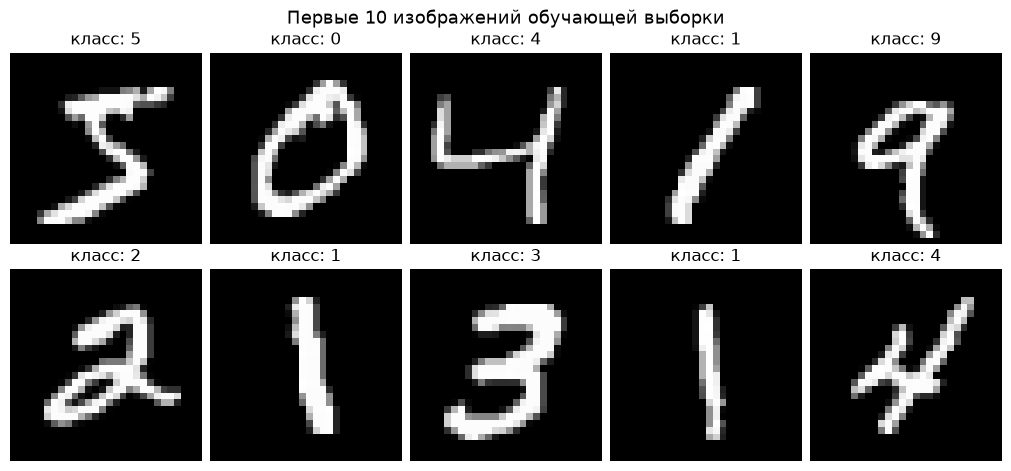

In [16]:
print(f"Обучающая выборка: {train_images.shape[0]} изображений")
print(f"Тестовая выборка:  {test_images.shape[0]} изображений")
print(f"Форма одного изображения: {train_images.shape[1]} x {train_images.shape[2]} пикселей")
print(f"Форма массива изображений train: {train_images.shape}, dtype: {train_images.dtype}")
print(f"Форма массива меток train: {train_labels.shape}, dtype: {train_labels.dtype}")
print(f"Число классов: {len(np.unique(train_labels))}, метки: {np.unique(train_labels)}")
print(f"Число примеров по классам train: {np.bincount(train_labels.astype(int))}")

fig, axes = plt.subplots(2, 5, figsize=(10, 4.6), constrained_layout=True)
for ax, img, label in zip(axes.flat, train_images[:10], train_labels[:10]):
    ax.imshow(img, cmap="gray")
    ax.set_title(f"класс: {label}")
    ax.axis("off")
fig.suptitle("Первые 10 изображений обучающей выборки", fontsize=13)
plt.show()

ПОдготовка данных.

Разворачиваем изображения 28х28 в одномерные векторы длины 784
Нормализуем пиксели в [0,1]
Метки классов переводятся в one-hot кодировку

In [17]:
X_train = train_images.reshape(train_images.shape[0], -1).astype(np.float32) / 255.0
X_test = test_images.reshape(test_images.shape[0], -1).astype(np.float32) / 255.0
y_train = train_labels.astype(np.int64)
y_test = test_labels.astype(np.int64)

N_CLASSES = 10

Y_train_onehot = np.eye(N_CLASSES, dtype=np.float32)[y_train]

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}, Y_train_onehot: {Y_train_onehot.shape}")
print(f"Диапазон пикселей после нормировки: [{X_train.min():.1f}, {X_train.max():.1f}]")
print(f"One-hot метка первой цифры ({y_train[0]}): {Y_train_onehot[0]}")


X_train: (60000, 784), X_test: (10000, 784)
y_train: (60000,), Y_train_onehot: (60000, 10)
Диапазон пикселей после нормировки: [0.0, 1.0]
One-hot метка первой цифры (5): [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


Реализация нейронной сети

In [18]:
class TwoLayerNeuralNet:
    """Двухслойная полносвязная сеть: 784 -> s нейронов (ReLU) -> 10 (softmax)."""

    def __init__(self, n_inputs=784, n_hidden=300, n_outputs=N_CLASSES, init="he", seed=42):
        rng = np.random.default_rng(seed)
        he = init == "he"
        self.W1 = rng.normal(0.0, np.sqrt(2.0 / n_inputs) if he else 0.01,
                             (n_inputs, n_hidden)).astype(np.float32)
        self.b1 = np.zeros(n_hidden, dtype=np.float32)
        self.W2 = rng.normal(0.0, np.sqrt(2.0 / n_hidden) if he else 0.01,
                             (n_hidden, n_outputs)).astype(np.float32)
        self.b2 = np.zeros(n_outputs, dtype=np.float32)

    # ---------- прямое распространение ----------
    def forward(self, X):
        Z1 = X @ self.W1 + self.b1            # (B, s)
        A1 = np.maximum(Z1, 0.0)              # ReLU
        Z2 = A1 @ self.W2 + self.b2           # (B, k)
        return Z1, A1, Z2

    @staticmethod
    def softmax(Z2):
        Z2 = Z2 - Z2.max(axis=1, keepdims=True)  # сдвиг для численной устойчивости
        e = np.exp(Z2)
        return e / e.sum(axis=1, keepdims=True)

    def predict_proba(self, X):
        return self.softmax(self.forward(X)[2])

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

    # ---------- обратное распространение ----------
    def backward(self, X, Z1, A1, P, Y):
        B = X.shape[0]
        Delta2 = (P - Y) / B                       # dL/dZ2 = (P - Y)/B
        dW2 = A1.T @ Delta2                        # dL/dW2 = A1^T @ Delta2
        db2 = Delta2.sum(axis=0)                   # сумма по строкам пачки
        Delta1 = (Delta2 @ self.W2.T) * (Z1 > 0)   # через производную ReLU
        dW1 = X.T @ Delta1                         # dL/dW1 = X^T @ Delta1
        db1 = Delta1.sum(axis=0)
        return dW1, db1, dW2, db2

    def train_step(self, X_batch, Y_batch, lr):
        """Один шаг SGD на пачке: forward -> backward -> коррекция весов."""
        Z1, A1, Z2 = self.forward(X_batch)
        P = self.softmax(Z2)
        dW1, db1, dW2, db2 = self.backward(X_batch, Z1, A1, P, Y_batch)
        self.W1 -= lr * dW1
        self.b1 -= lr * db1
        self.W2 -= lr * dW2
        self.b2 -= lr * db2
        return float(-np.log(P[np.arange(len(X_batch)), Y_batch.argmax(axis=1)] + 1e-12).mean())

Проверяем ошибку до обучения, примерно близка к ln(10) то есть полностью случайные предсказания

In [19]:
check_model = TwoLayerNeuralNet(n_hidden=300, seed=0)
Z1c, A1c, Z2c = check_model.forward(X_train[:8])
P0 = check_model.softmax(Z2c)

P1k = check_model.predict_proba(X_train[:1000])
print(f"Loss до обучения (1000 примеров): {-np.log(P1k[np.arange(1000), y_train[:1000]]).mean():.3f} "
      f"(ln(10) = {np.log(10):.3f}; ")

Loss до обучения (1000 примеров): 2.452 (ln(10) = 2.303; 


Обучение

In [20]:
def classification_error(model, X, y, chunk=2000):
    """Доля ошибочно классифицированных примеров (ошибка классификации)."""
    preds = np.concatenate([model.predict(X[i:i + chunk]) for i in range(0, len(X), chunk)])
    return float(1.0 - (preds == y).mean())


def train_network(model, X, Y_onehot, y, epochs, lr, batch_size, seed=0, verbose=True):
    """Обучение SGD по пачкам; порядок примеров перемешивается каждую эпоху."""
    rng = np.random.default_rng(seed)
    n = len(X)
    history = {"loss": [], "train_error": [], "epoch_time": []}
    total_start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        epoch_start = time.perf_counter()
        perm = rng.permutation(n)                    # перемешивание примеров
        losses = []
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            losses.append(model.train_step(X[idx], Y_onehot[idx], lr))

        epoch_time = time.perf_counter() - epoch_start
        train_err = classification_error(model, X, y)   # Общая ошибка
        history["loss"].append(float(np.mean(losses)))
        history["train_error"].append(train_err)
        history["epoch_time"].append(epoch_time)
        if verbose:
            print(f"Эпоха {epoch:2d}/{epochs} | время: {epoch_time:6.2f} с | "
                  f"loss: {np.mean(losses):.4f} | ошибка на train: {train_err * 100:.2f}%")

    total_time = time.perf_counter() - total_start
    print(f"\nОбщее время обучения: {total_time:.1f} с")
    return history


собственно обучение

In [21]:
S = 300               # число скрытых нейронов
LEARNING_RATE = 0.1   # скорость обучения
BATCH_SIZE = 64       # размер пачки (диапазон по методичке: 8–64)
EPOCHS = 20           # число эпох

model = TwoLayerNeuralNet(n_hidden=S, seed=42)
history = train_network(model, X_train, Y_train_onehot, y_train,
                        epochs=EPOCHS, lr=LEARNING_RATE, batch_size=BATCH_SIZE)

Эпоха  1/20 | время:   0.67 с | loss: 0.3525 | ошибка на train: 5.85%
Эпоха  2/20 | время:   0.60 с | loss: 0.1840 | ошибка на train: 4.53%
Эпоха  3/20 | время:   0.58 с | loss: 0.1366 | ошибка на train: 3.10%
Эпоха  4/20 | время:   0.58 с | loss: 0.1099 | ошибка на train: 2.66%
Эпоха  5/20 | время:   0.58 с | loss: 0.0913 | ошибка на train: 2.20%
Эпоха  6/20 | время:   0.59 с | loss: 0.0781 | ошибка на train: 1.90%
Эпоха  7/20 | время:   0.59 с | loss: 0.0677 | ошибка на train: 1.57%
Эпоха  8/20 | время:   0.60 с | loss: 0.0600 | ошибка на train: 1.27%
Эпоха  9/20 | время:   0.60 с | loss: 0.0529 | ошибка на train: 1.25%
Эпоха 10/20 | время:   0.58 с | loss: 0.0475 | ошибка на train: 1.08%
Эпоха 11/20 | время:   0.60 с | loss: 0.0424 | ошибка на train: 0.88%
Эпоха 12/20 | время:   0.62 с | loss: 0.0385 | ошибка на train: 0.71%
Эпоха 13/20 | время:   0.58 с | loss: 0.0346 | ошибка на train: 0.63%
Эпоха 14/20 | время:   0.63 с | loss: 0.0314 | ошибка на train: 0.61%
Эпоха 15/20 | время:

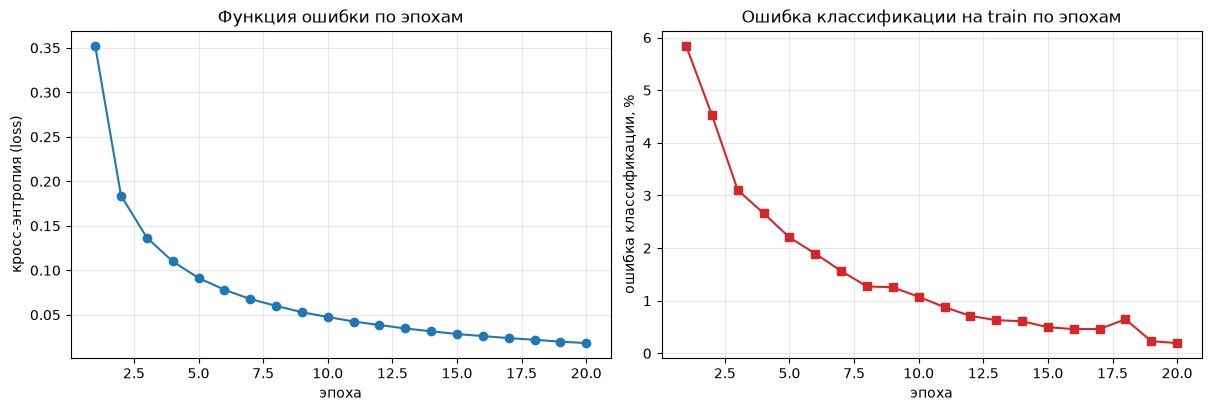

Среднее время эпохи: 0.60 с


In [22]:
# Кривые обучения: функция ошибки и ошибка классификации по эпохам
epochs_axis = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

axes[0].plot(epochs_axis, history["loss"], "o-", color="tab:blue")
axes[0].set_xlabel("эпоха")
axes[0].set_ylabel("кросс-энтропия (loss)")
axes[0].set_title("Функция ошибки по эпохам")
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_axis, 100 * np.array(history["train_error"]), "s-", color="tab:red")
axes[1].set_xlabel("эпоха")
axes[1].set_ylabel("ошибка классификации, %")
axes[1].set_title("Ошибка классификации на train по эпохам")
axes[1].grid(alpha=0.3)
plt.show()

print(f"Среднее время эпохи: {np.mean(history['epoch_time']):.2f} с")

После обучения оценим ошибку классификации на отложенной тестовой выборке из 10 000 изображений, которые сеть не видела в процессе обучения.

In [23]:
test_error = classification_error(model, X_test, y_test)

print(f"Тестовая выборка: {len(X_test)} изображений")
print(f"Ошибка классификации на тесте: {test_error * 100:.2f}%")
print(f"Точность классификации на тесте: {(1 - test_error) * 100:.2f}%")


Тестовая выборка: 10000 изображений
Ошибка классификации на тесте: 1.80%
Точность классификации на тесте: 98.20%


Анализ ошибок

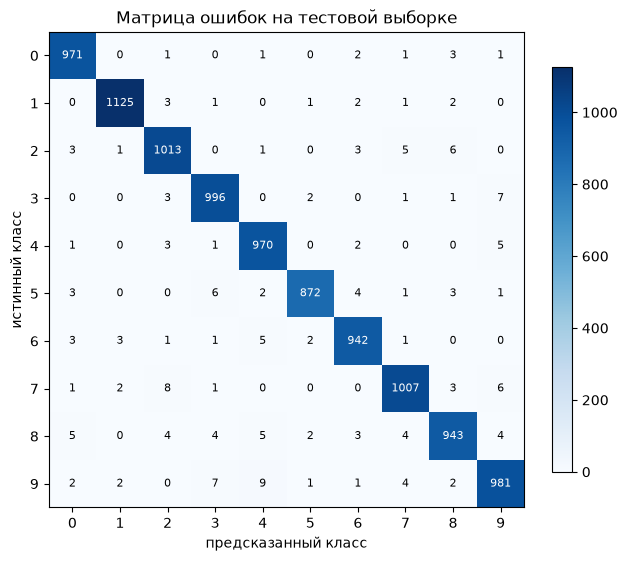

In [24]:
y_pred = model.predict(X_test)
confusion = np.zeros((N_CLASSES, N_CLASSES), dtype=int)
for true_label, pred_label in zip(y_test, y_pred):
    confusion[true_label, pred_label] += 1

fig, ax = plt.subplots(figsize=(6.5, 5.5), constrained_layout=True)
im = ax.imshow(confusion, cmap="Blues")
ax.set_xticks(range(N_CLASSES))
ax.set_yticks(range(N_CLASSES))
ax.set_xlabel("предсказанный класс")
ax.set_ylabel("истинный класс")
ax.set_title("Матрица ошибок на тестовой выборке")
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        ax.text(j, i, confusion[i, j], ha="center", va="center", fontsize=8,
                color="white" if confusion[i, j] > confusion.max() / 2 else "black")
fig.colorbar(im, ax=ax, shrink=0.85)
plt.show()

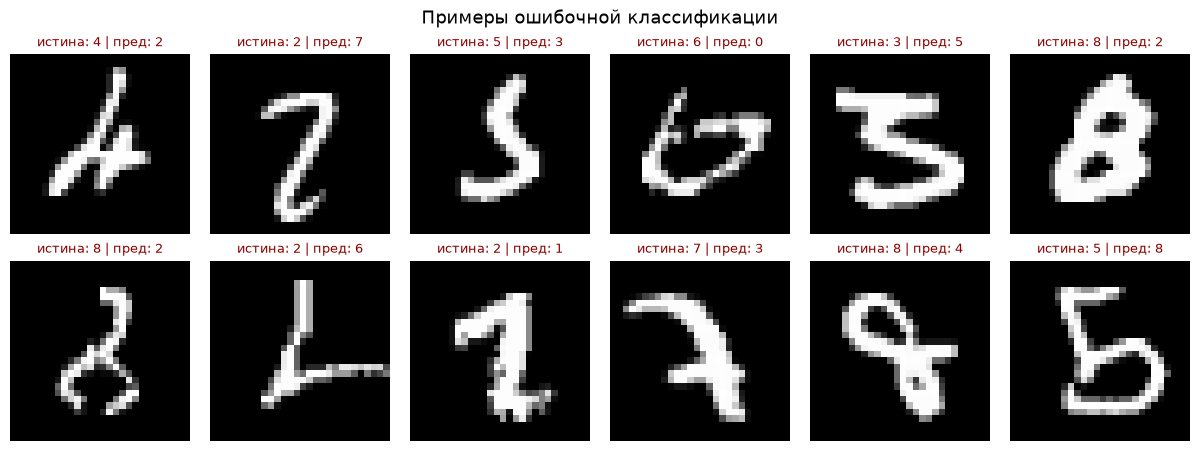

Всего ошибок: 180 из 10000


In [25]:
wrong_idx = np.where(y_pred != y_test)[0][:12]

fig, axes = plt.subplots(2, 6, figsize=(12, 4.4), constrained_layout=True)
for ax, i in zip(axes.flat, wrong_idx):
    ax.imshow(test_images[i], cmap="gray")
    ax.set_title(f"истина: {y_test[i]} | пред: {y_pred[i]}", fontsize=9, color="darkred")
    ax.axis("off")
fig.suptitle("Примеры ошибочной классификации", fontsize=13)
plt.show()

print(f"Всего ошибок: {(y_pred != y_test).sum()} из {len(y_test)}")

Ради интереса пробуем уменьшить размер скрытого слоя, компенсировав это малой скоростью обучения и большим числом эпох

In [26]:
S = 100               # число скрытых нейронов
LEARNING_RATE = 0.05   # скорость обучения
BATCH_SIZE = 64       # размер пачки (диапазон по методичке: 8–64)
EPOCHS = 50           # число эпох

model = TwoLayerNeuralNet(n_hidden=S, seed=42)
history = train_network(model, X_train, Y_train_onehot, y_train,
                        epochs=EPOCHS, lr=LEARNING_RATE, batch_size=BATCH_SIZE)

Эпоха  1/50 | время:   0.39 с | loss: 0.4662 | ошибка на train: 8.09%
Эпоха  2/50 | время:   0.39 с | loss: 0.2616 | ошибка на train: 6.75%
Эпоха  3/50 | время:   0.38 с | loss: 0.2114 | ошибка на train: 5.20%
Эпоха  4/50 | время:   0.38 с | loss: 0.1796 | ошибка на train: 4.57%
Эпоха  5/50 | время:   0.38 с | loss: 0.1570 | ошибка на train: 4.04%
Эпоха  6/50 | время:   0.38 с | loss: 0.1405 | ошибка на train: 3.54%
Эпоха  7/50 | время:   0.41 с | loss: 0.1269 | ошибка на train: 3.32%
Эпоха  8/50 | время:   0.40 с | loss: 0.1167 | ошибка на train: 2.99%
Эпоха  9/50 | время:   0.43 с | loss: 0.1076 | ошибка на train: 2.71%
Эпоха 10/50 | время:   0.39 с | loss: 0.0999 | ошибка на train: 2.56%
Эпоха 11/50 | время:   0.38 с | loss: 0.0932 | ошибка на train: 2.45%
Эпоха 12/50 | время:   0.39 с | loss: 0.0876 | ошибка на train: 2.14%
Эпоха 13/50 | время:   0.39 с | loss: 0.0817 | ошибка на train: 2.02%
Эпоха 14/50 | время:   0.39 с | loss: 0.0774 | ошибка на train: 1.92%
Эпоха 15/50 | время:

Попробуем увеличить размер скрытого слоя и ускорить процесс обучения

In [27]:
S = 1000               # число скрытых нейронов
LEARNING_RATE = 0.1   # скорость обучения
BATCH_SIZE = 64       # размер пачки (диапазон по методичке: 8–64)
EPOCHS = 15           # число эпох

model = TwoLayerNeuralNet(n_hidden=S, seed=42)
history = train_network(model, X_train, Y_train_onehot, y_train,
                        epochs=EPOCHS, lr=LEARNING_RATE, batch_size=BATCH_SIZE)

Эпоха  1/15 | время:   3.05 с | loss: 0.3330 | ошибка на train: 5.37%
Эпоха  2/15 | время:   3.01 с | loss: 0.1734 | ошибка на train: 4.02%
Эпоха  3/15 | время:   2.94 с | loss: 0.1254 | ошибка на train: 2.67%
Эпоха  4/15 | время:   2.96 с | loss: 0.0989 | ошибка на train: 2.31%
Эпоха  5/15 | время:   3.03 с | loss: 0.0810 | ошибка на train: 1.85%
Эпоха  6/15 | время:   3.06 с | loss: 0.0684 | ошибка на train: 1.46%
Эпоха  7/15 | время:   3.01 с | loss: 0.0586 | ошибка на train: 1.21%
Эпоха  8/15 | время:   3.05 с | loss: 0.0508 | ошибка на train: 1.01%
Эпоха  9/15 | время:   2.93 с | loss: 0.0444 | ошибка на train: 1.04%
Эпоха 10/15 | время:   3.00 с | loss: 0.0393 | ошибка на train: 0.79%
Эпоха 11/15 | время:   3.04 с | loss: 0.0346 | ошибка на train: 0.61%
Эпоха 12/15 | время:   3.06 с | loss: 0.0311 | ошибка на train: 0.48%
Эпоха 13/15 | время:   3.16 с | loss: 0.0276 | ошибка на train: 0.42%
Эпоха 14/15 | время:   3.07 с | loss: 0.0246 | ошибка на train: 0.36%
Эпоха 15/15 | время: